In [1]:
import numpy as np
import matplotlib.pyplot as plt

from som_rl.som.som_backend import SharpZSOMBackend, SharpZBackendConfig
from som_rl.env.schedules import SchedulerConfig, make_scheduler
from som_rl.env.env import SOMEnergyEnvConfig, EnvTeleportNodeRandomBin

from som_rl.eval.rollout import run_episode
from som_rl.eval.ideal_som import get_perfect_bins, plot_bins_triptych

import torch

print("torch:", torch.__version__)

torch: 2.10.0


In [2]:
# Load data and build a fresh backend
DATA = "data"  # adjust if needed

npz = np.load(f"{DATA}/correlations_dl/npairs_compact.npz")
dd, dr, rd, rr = npz["dd"], npz["dr"], npz["rd"], npz["rr"]

node_indices_photo = np.load(f"{DATA}/node_indices_fc.npy")  # (Nphot,)
initial_node_bins  = np.load(f"{DATA}/nodes_labels_initial_fc_200_ext.npy")  # (40000,)
reference_labels   = np.load(f"{DATA}/reference_labels_fc_fc.npy")  # (Nref,) in [0..10]

weighted_clusters  = np.load(f"{DATA}/weighted_clusters_5c_1t200.npy")  # (L,40000)
umatrix = np.load(f"{DATA}/umat.npy")  # (200,200)

b_cfg = SharpZBackendConfig(
    grid_shape=(200, 200),
    num_bins=11,
    objective_mode="energy",
    proposal_bin_mode="uniform_other",
)


def make_backend():
    return SharpZSOMBackend(
        cfg=b_cfg,
        dd=dd, dr=dr, rd=rd, rr=rr,
        node_indices_photo=node_indices_photo,
        initial_node_bins=initial_node_bins,
        reference_labels=reference_labels,
        umatrix=umatrix,
        weighted_clusters=weighted_clusters,
    )

som = make_backend()
print("Initial energy_E():", som.energy_E())

Initial energy_E(): 0.023775093565945846


In [3]:
# Perfect SOM bins for diagnostics
perfect_bins = get_perfect_bins()
print("Perfect bins shape:", perfect_bins.shape)


Perfect bins shape: (40000,)


In [ ]:
# Helper: build a pure SharpZ env with LevelHits scheduler at fixed levels

levels = (30,)
HITS_PER_LEVEL = 200
MAX_STEPS = 5000

sched_cfg = SchedulerConfig(
    max_steps=MAX_STEPS,
    level_min=min(levels),
    level_max=max(levels),
    level_list=levels,
    min_accepts_per_level=HITS_PER_LEVEL,
    reset_temp_on_level_up=False,
    floor_fixed=5e-4,
    T_max = 1.0,
    T_min = 0.9

)

env_cfg = SOMEnergyEnvConfig(
    grid_shape=(200, 200),
    obs_mode="global",          # full map for diagnostics; policy ignores it in pure SharpZ
    patch_size=9,
    include_umatrix=True,
    include_cluster_features=True,
    include_empty_mask=True,
    include_visit_count=True,
    include_recent_mask=True,
    recent_cooldown_steps=10,
    max_steps=MAX_STEPS,
    initial_level=levels[0],
    initial_temperature=1.0,
    reward_type="deltaE",
    use_tanh_reward=True,
    reward_tanh_temperature=1e-2,
    reward_energy_scale=1.0,
    clip_reward=1.0,
    # For a pure SharpZ baseline we typically do not use strong penalties here.
    reject_penalty=0.0,
    noop_penalty=0.0,
    use_greedy_bin_for_node=False,
    use_env_max_steps=False,
)

backend = make_backend()
scheduler = make_scheduler("level_hits", sched_cfg)

sharp_env = EnvTeleportNodeRandomBin(backend, env_cfg, scheduler=scheduler)
obs, info = sharp_env.reset()
print("SharpZ env reset: level=", info.get("level"), "energy=", info.get("energy"))

SharpZ env reset: level= 30 energy= 0.023775093565945846


In [48]:
from som_rl.som.som_backend import SharpZSOMBackend

def _backend_get_reward(self):
    # use energy_E as the scalar trace/reward
    return float(self.energy_E())

SharpZSOMBackend.get_reward = _backend_get_reward  # monkey-patch once

In [49]:
# Simple SharpZ policy: choose a random eligible node each step
# (you can later swap this for a greedy-node policy or other heuristics)

import numpy.random as npr


def sharpz_random_policy(obs, rng: np.random.Generator):
    # EnvTeleportNodeRandomBin expects an integer node index in [0, H*W)
    return rng.integers(0, sharp_env.H * sharp_env.W, dtype=np.int64)


art = run_episode(sharp_env, sharpz_random_policy, max_steps=MAX_STEPS, seed=0)
print("Steps taken:", len(art.log_df))
print("Trace start/end/best:", art.trace_start, art.trace_end, art.trace_best, "best at step", art.best_step)

Steps taken: 5000
Trace start/end/best: 0.023775093565945846 0.02641768244187078 0.02641768244187078 best at step 3136


Start vs perfect:


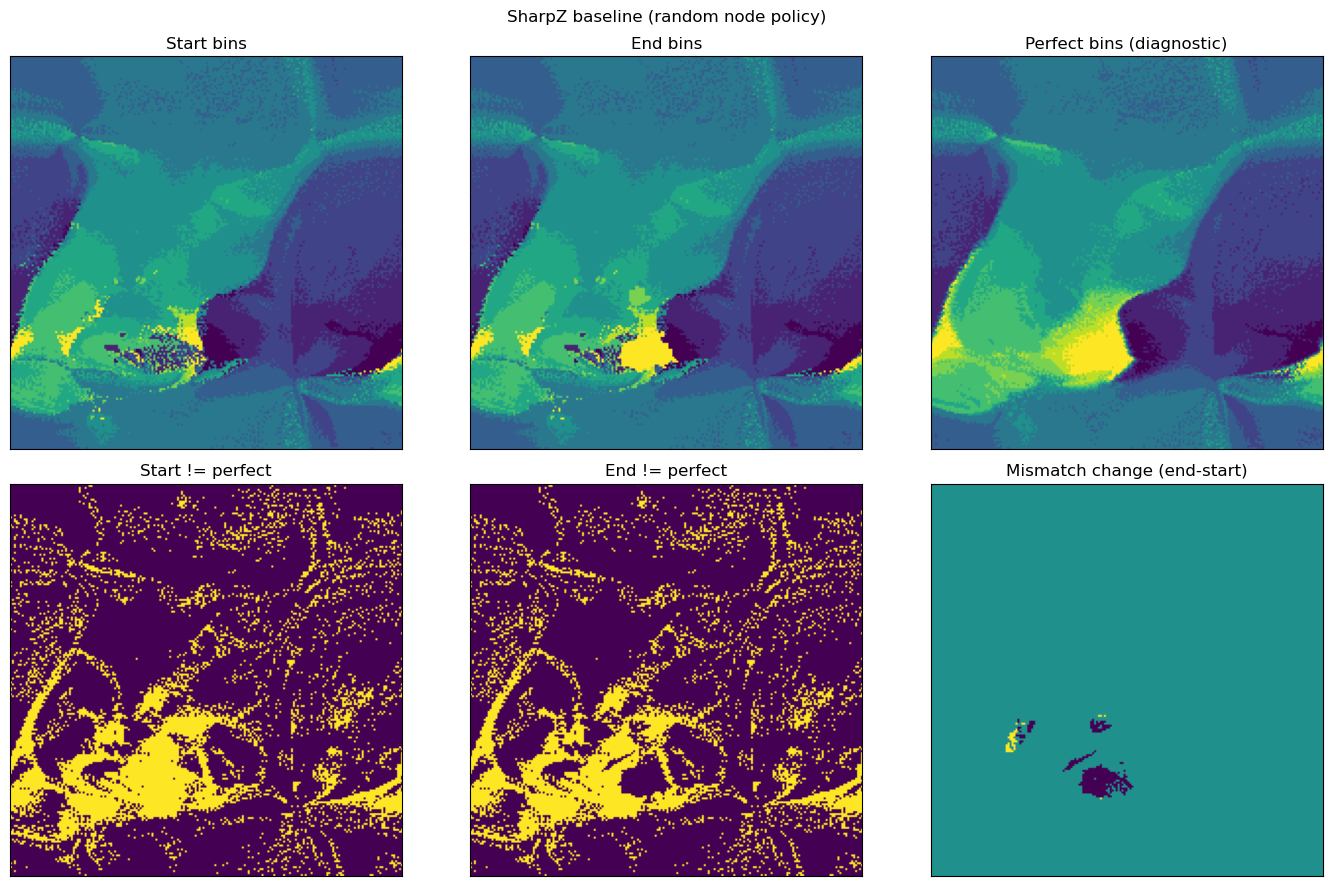

Match to perfect: start=0.795, end=0.803, Δ=+0.008


In [62]:
# Compare starting/ending/best bins to the "perfect" SOM

start_bins = art.bins_start
end_bins   = art.bins_end
best_bins  = art.bins_best

print("Start vs perfect:")
plot_bins_triptych(start_bins, end_bins, perfect_bins, title="SharpZ baseline (random node policy)")

Stage 2 (L=50): steps 5000 E_end 0.027121560383595544


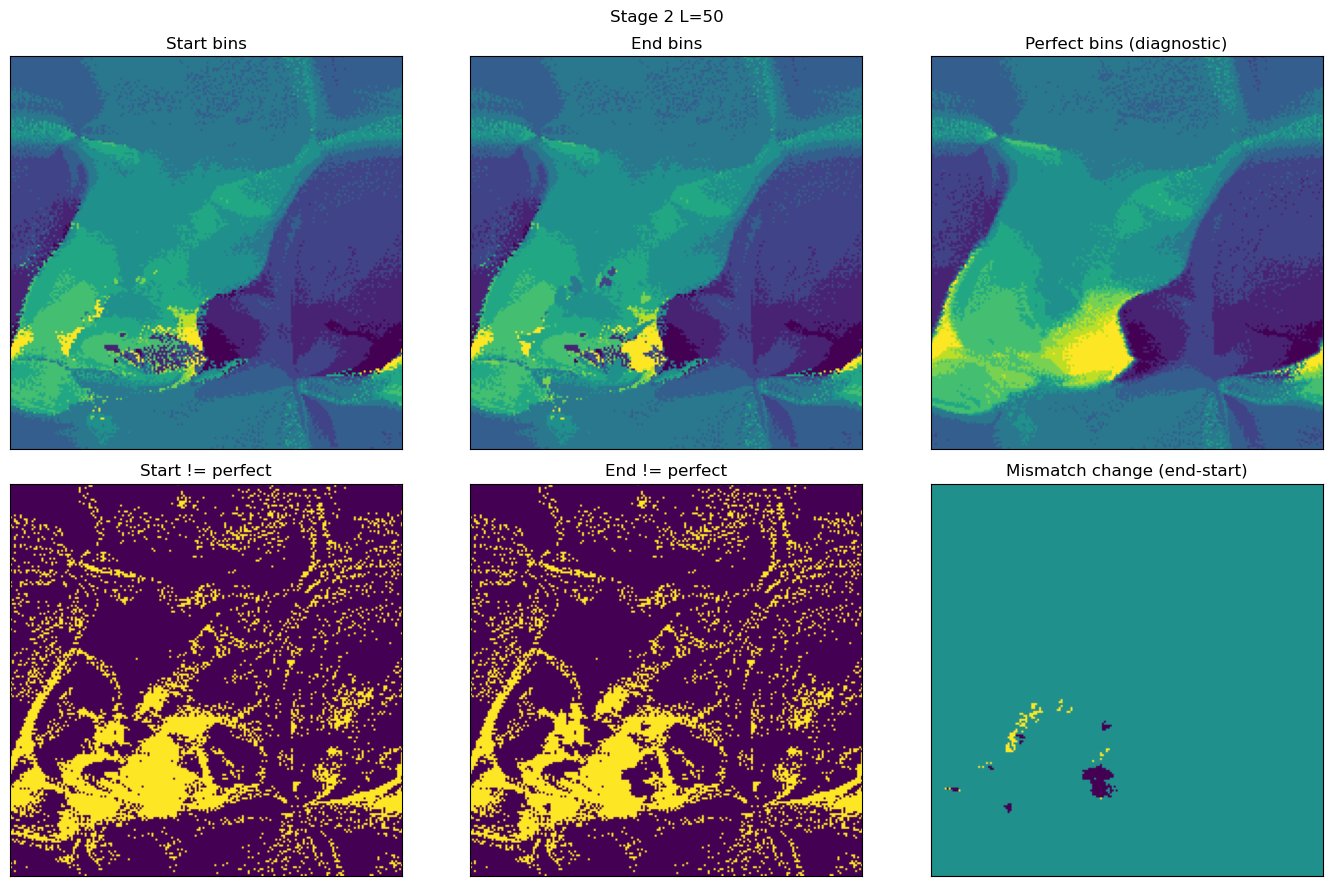

Match to perfect: start=0.795, end=0.797, Δ=+0.003


In [61]:
sched2_cfg = SchedulerConfig(
    max_steps=MAX_STEPS,
    level_min=50,
    level_max=50,
    level_list=(50,),
    min_accepts_per_level=HITS_PER_LEVEL,
    reset_temp_on_level_up=False,
    floor_fixed=1e-4,
    T_max = 0.9,
    T_min = 0.75
)
sched2 = make_scheduler("level_hits", sched2_cfg)

sharp_env2 = sharp_env
sharp_env2.scheduler = sched2

art2 = run_episode(sharp_env2, sharpz_random_policy, max_steps=MAX_STEPS, seed=1)

print("Stage 2 (L=50): steps", len(art2.log_df), "E_end", art2.trace_end)

plot_bins_triptych(art2.bins_start, art2.bins_end, perfect_bins, title="Stage 2 L=50")

Stage 2 (L=50): steps 5000 E_end 0.02607367492308217


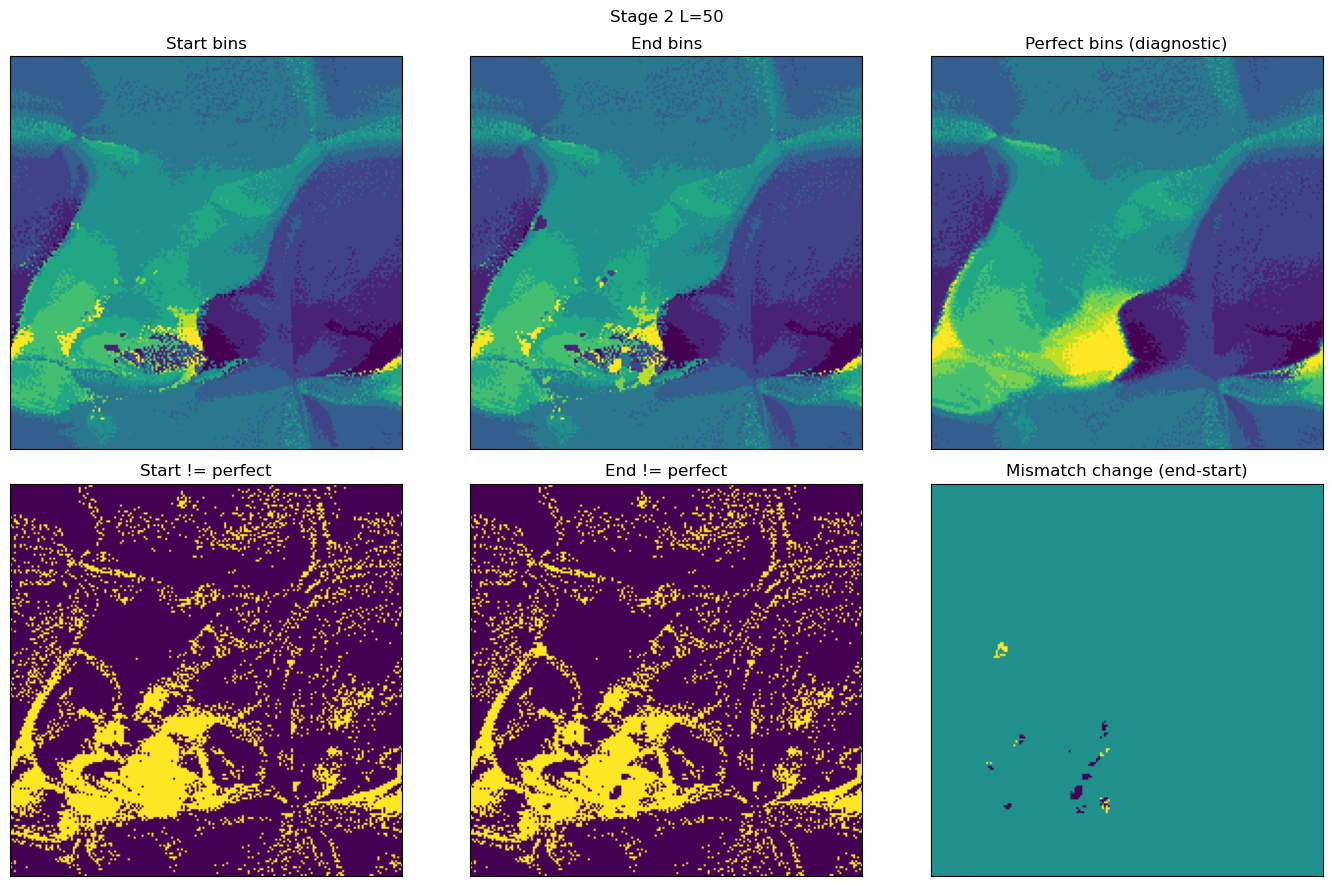

Match to perfect: start=0.795, end=0.796, Δ=+0.002


In [ ]:
sched2_cfg = SchedulerConfig(
    max_steps=MAX_STEPS,
    level_min=80,
    level_max=80,
    level_list=(80,),
    min_accepts_per_level=HITS_PER_LEVEL,
    reset_temp_on_level_up=False,
    floor_fixed=5e-5,
    T_max = 0.75,
    T_min = 0.3
)
sched2 = make_scheduler("level_hits", sched2_cfg)

sharp_env2 = sharp_env
sharp_env2.scheduler = sched2

art2 = run_episode(sharp_env2, sharpz_random_policy, max_steps=MAX_STEPS, seed=1)

print("Stage 2 (L=80): steps", len(art2.log_df), "E_end", art2.trace_end)

plot_bins_triptych(art2.bins_start, art2.bins_end, perfect_bins, title="Stage 2 L=50")

Stage 2 (L=50): steps 5000 E_end 0.025270729440057368


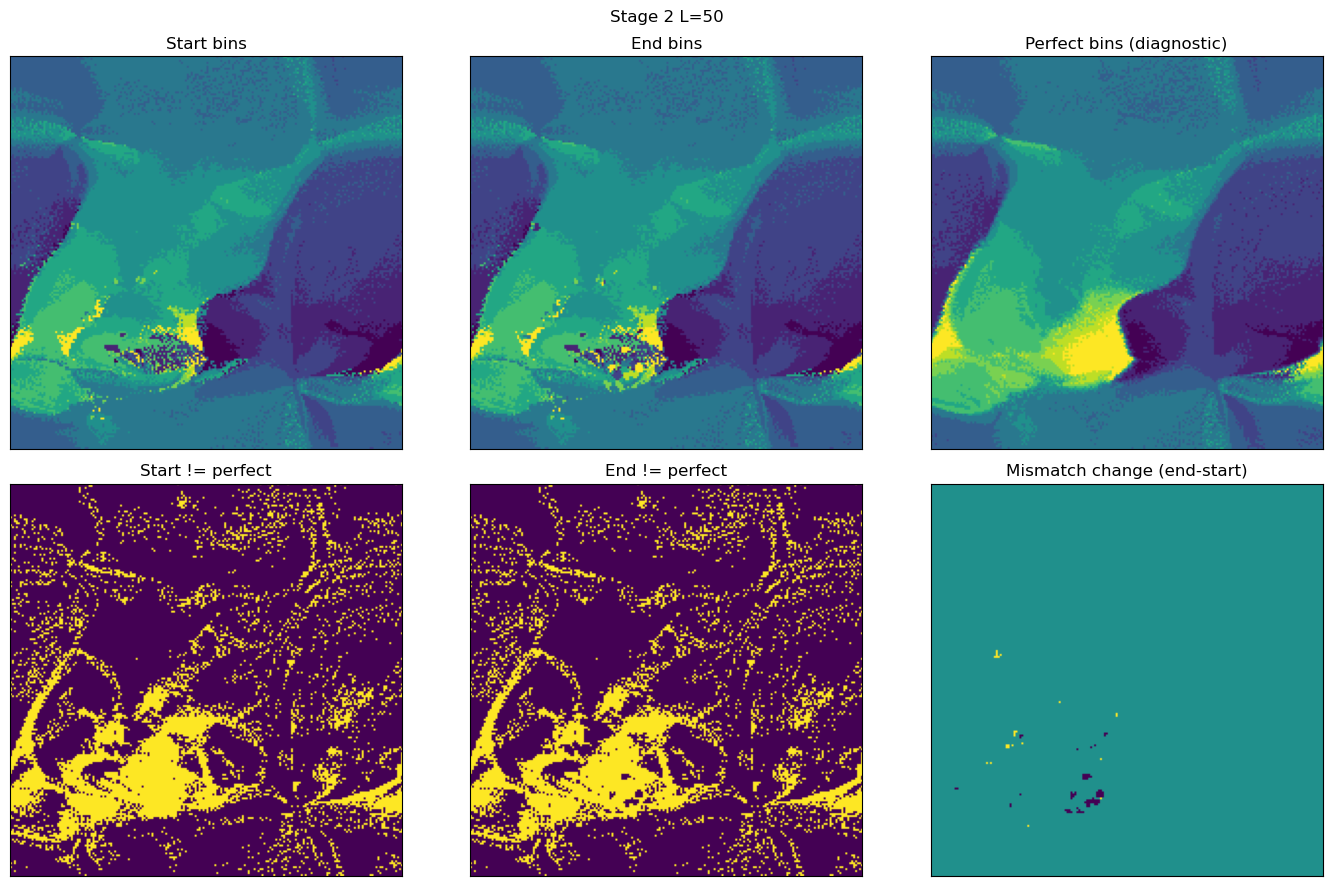

Match to perfect: start=0.795, end=0.796, Δ=+0.001


In [ ]:
sched2_cfg = SchedulerConfig(
    max_steps=20000,
    level_min=120,
    level_max=120,
    level_list=(120,),
    min_accepts_per_level=200,
    reset_temp_on_level_up=False,
    floor_fixed=1e-5,
    T_max = 0.75,
    T_min = 0.3
)
sched2 = make_scheduler("level_hits", sched2_cfg)

sharp_env2 = sharp_env
sharp_env2.scheduler = sched2

art2 = run_episode(sharp_env2, sharpz_random_policy, max_steps=20000, seed=1)

print("Stage 2 (L=120): steps", len(art2.log_df), "E_end", art2.trace_end)

plot_bins_triptych(art2.bins_start, art2.bins_end, perfect_bins, title="Stage 2 L=50")

Stage 2 (L=50): steps 5000 E_end 0.024752733206734587


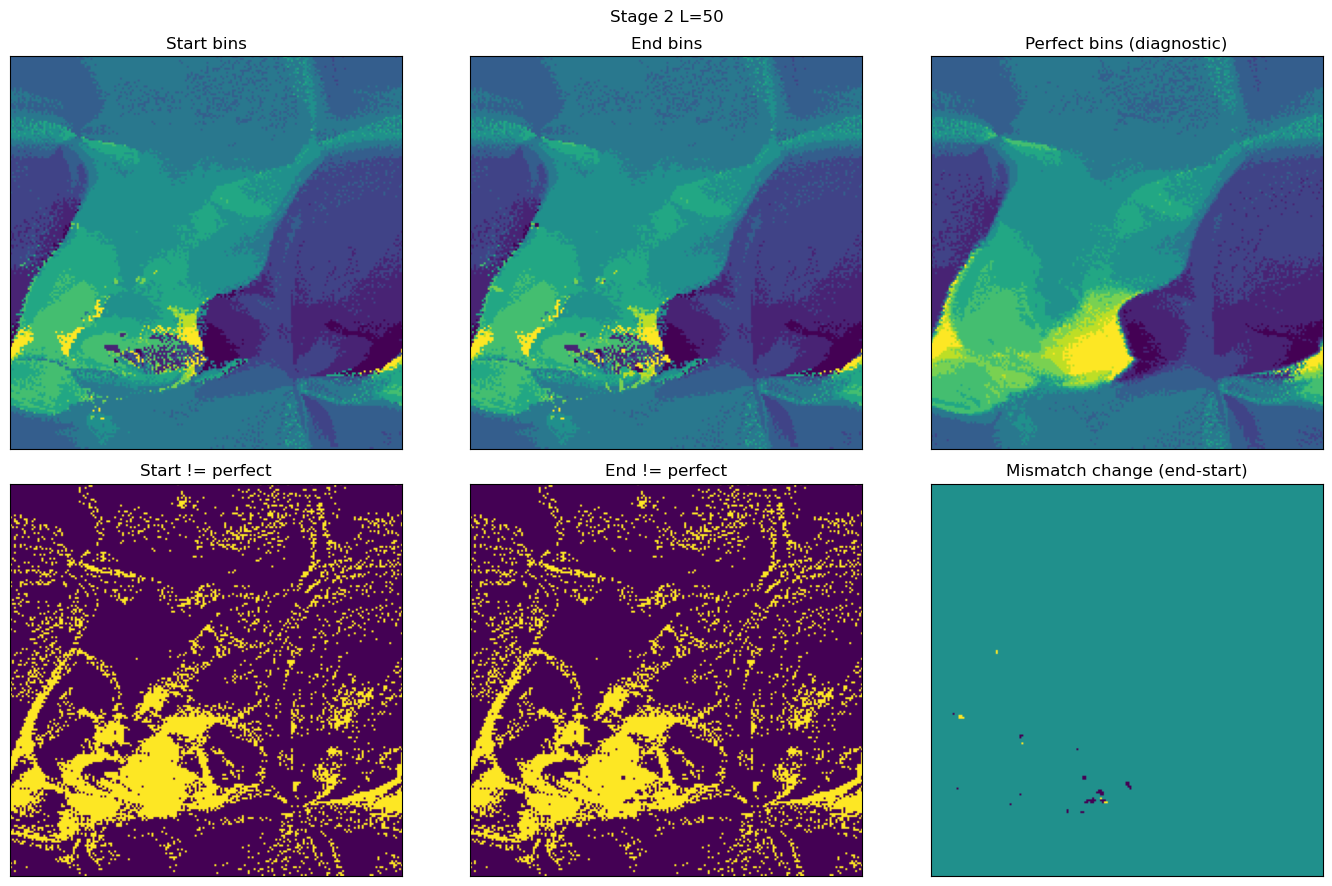

Match to perfect: start=0.795, end=0.796, Δ=+0.001


In [ ]:
sched2_cfg = SchedulerConfig(
    max_steps=200000,
    level_min=150,
    level_max=150,
    level_list=(150,),
    min_accepts_per_level=300,
    reset_temp_on_level_up=False,
    floor_fixed=1e-5,
    T_max = 0.3,
    T_min = 0.05
)
sched2 = make_scheduler("level_hits", sched2_cfg)

sharp_env2 = sharp_env
sharp_env2.scheduler = sched2

art2 = run_episode(sharp_env2, sharpz_random_policy, max_steps=20000, seed=1)

print("Stage 2 (L=150): steps", len(art2.log_df), "E_end", art2.trace_end)

plot_bins_triptych(art2.bins_start, art2.bins_end, perfect_bins, title="Stage 2 L=50")

In [75]:
import pandas as pd

df = art.log_df.copy()

# Derive a per-step trace delta if delta_reward is not filled
if "delta_reward" not in df or (df["delta_reward"] == 0).all():
    df["delta_trace"] = df["reward_trace"].diff().fillna(0.0)
else:
    df["delta_trace"] = df["delta_reward"]

# Define hits: accepted and not noop
df["hit"] = df["accepted"] & (~df["is_noop"])

# Per-level summaries
grp = df.groupby("level", dropna=True)

summary = pd.DataFrame({
    "steps": grp.size(),
    "hits": grp["hit"].sum(),
    "mean_trace": grp["reward_trace"].mean(),
    "start_trace": grp["reward_trace"].first(),
    "end_trace": grp["reward_trace"].last(),
    "mean_delta_pos": grp.apply(lambda g: g.loc[g["delta_trace"] > 0, "delta_trace"].mean() or 0.0),
})

summary["trace_gain"] = summary["end_trace"] - summary["start_trace"]
print(summary)

KeyError: 'accepted'